# Rules-based backtest

This notebook runs only the transparent weekly momentum strategy. The optional machine-learning comparison is in `Machine Learning Trade Model/notebooks/ml_trade_model.ipynb`.

In [1]:
import sys
from pathlib import Path

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in candidates if (path / 'src' / 'trading').is_dir()), None)
if project_root is None:
    raise RuntimeError('Could not locate the project root containing src/trading')
sys.path.insert(0, str(project_root / 'src'))
from trading.config import load_config
from trading.data import load_prices
from trading.risk import portfolio_risk_diagnostics, risk_diagnostics
from trading.strategy import weekly_momentum_weights
from trading.backtest import format_performance_report, run_backtest
from trading.visualization import plot_diagnostics, plot_periodic_returns
config = load_config(project_root / 'config.yaml')
prices = load_prices(project_root / 'data' / 'processed' / 'prices.parquet')
plot_start = None  # Set to '2020-01-01' to inspect a specific range.
plot_end = None    # Set to '2020-12-31'; leave both as None for full history.
risk_profile = 'balanced'  # Also try 'conservative' or 'aggressive'.
profile = config.values.get('risk_profiles', {}).get(risk_profile, {})
excluded_symbols = [symbol for asset_class in ('forex', 'bonds', 'commodities') for symbol in config.values.get('asset_classes', {}).get(asset_class, [])]
benchmark_fallback = True  # Hold SPY when no eligible momentum candidates exist.
print(f'Loaded {prices.shape[1]:,} symbols from {prices.index.min().date()} to {prices.index.max().date()}')


/Users/buji/Projects/Trading Algorithm for Financial Technology Club/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Loaded 555 symbols from 2012-01-02 to 2026-10-08


In [2]:
risk = risk_diagnostics(prices, config['benchmark'], config['forecast_horizon_days'], config['volatility_days'])
weights = weekly_momentum_weights(
    prices, config['benchmark'], profile.get('top_n', config['top_n']), config['lookback_days'], profile.get('skip_days', config['skip_days']),
    config['volatility_days'], profile.get('max_position_weight', config['max_position_weight']), profile.get('max_equity_exposure', config['max_equity_exposure']),
    config['defensive_exposure'], profile.get('stop_loss_pct', config['stop_loss_pct']), config['drawdown_start'],
    config['drawdown_full_defense'], volatility_target=profile.get('volatility_target', config['volatility_target']), excluded_symbols=excluded_symbols, benchmark_fallback=benchmark_fallback
)
ledger, holdings, trades = run_backtest(
    prices, weights, config['initial_capital'], config['commission_bps'],
    config['half_spread_bps'], config['slippage_bps'], config['market_impact_bps']
)
portfolio_risk = portfolio_risk_diagnostics(holdings, prices, config['benchmark'])
print('RULES-BASED MODEL')
print(format_performance_report(ledger, config['initial_capital']))
print(f'Trades recorded: {len(trades):,}')


RULES-BASED MODEL
Backtest Performance
--------------------
Initial capital:        $100,000.000
Final portfolio value:  $100,603.252
Total profit:           $603.252
Total return:           0.603%
Annualized return:      0.041%
Annualized volatility:  1.516%
Sharpe ratio:           0.034
Maximum drawdown:       -5.616%
Average turnover:       0.399%
Trades recorded: 459


(<Figure size 1600x1800 with 8 Axes>,
 array([<Axes: title={'center': 'Equity curve'}, ylabel='Portfolio value ($)'>,
        <Axes: title={'center': 'Cumulative return'}, ylabel='Return (%)'>,
        <Axes: title={'center': 'Drawdown'}>,
        <Axes: title={'center': 'Monthly trade count'}, ylabel='Trades'>,
        <Axes: title={'center': 'Monthly traded notional'}, ylabel='Notional ($)'>,
        <Axes: title={'center': 'Monthly net profit/loss'}, ylabel='Net P/L ($)'>,
        <Axes: title={'center': 'Rolling portfolio risk'}>,
        <Axes: title={'center': 'Exposure and position count'}>],
       dtype=object))

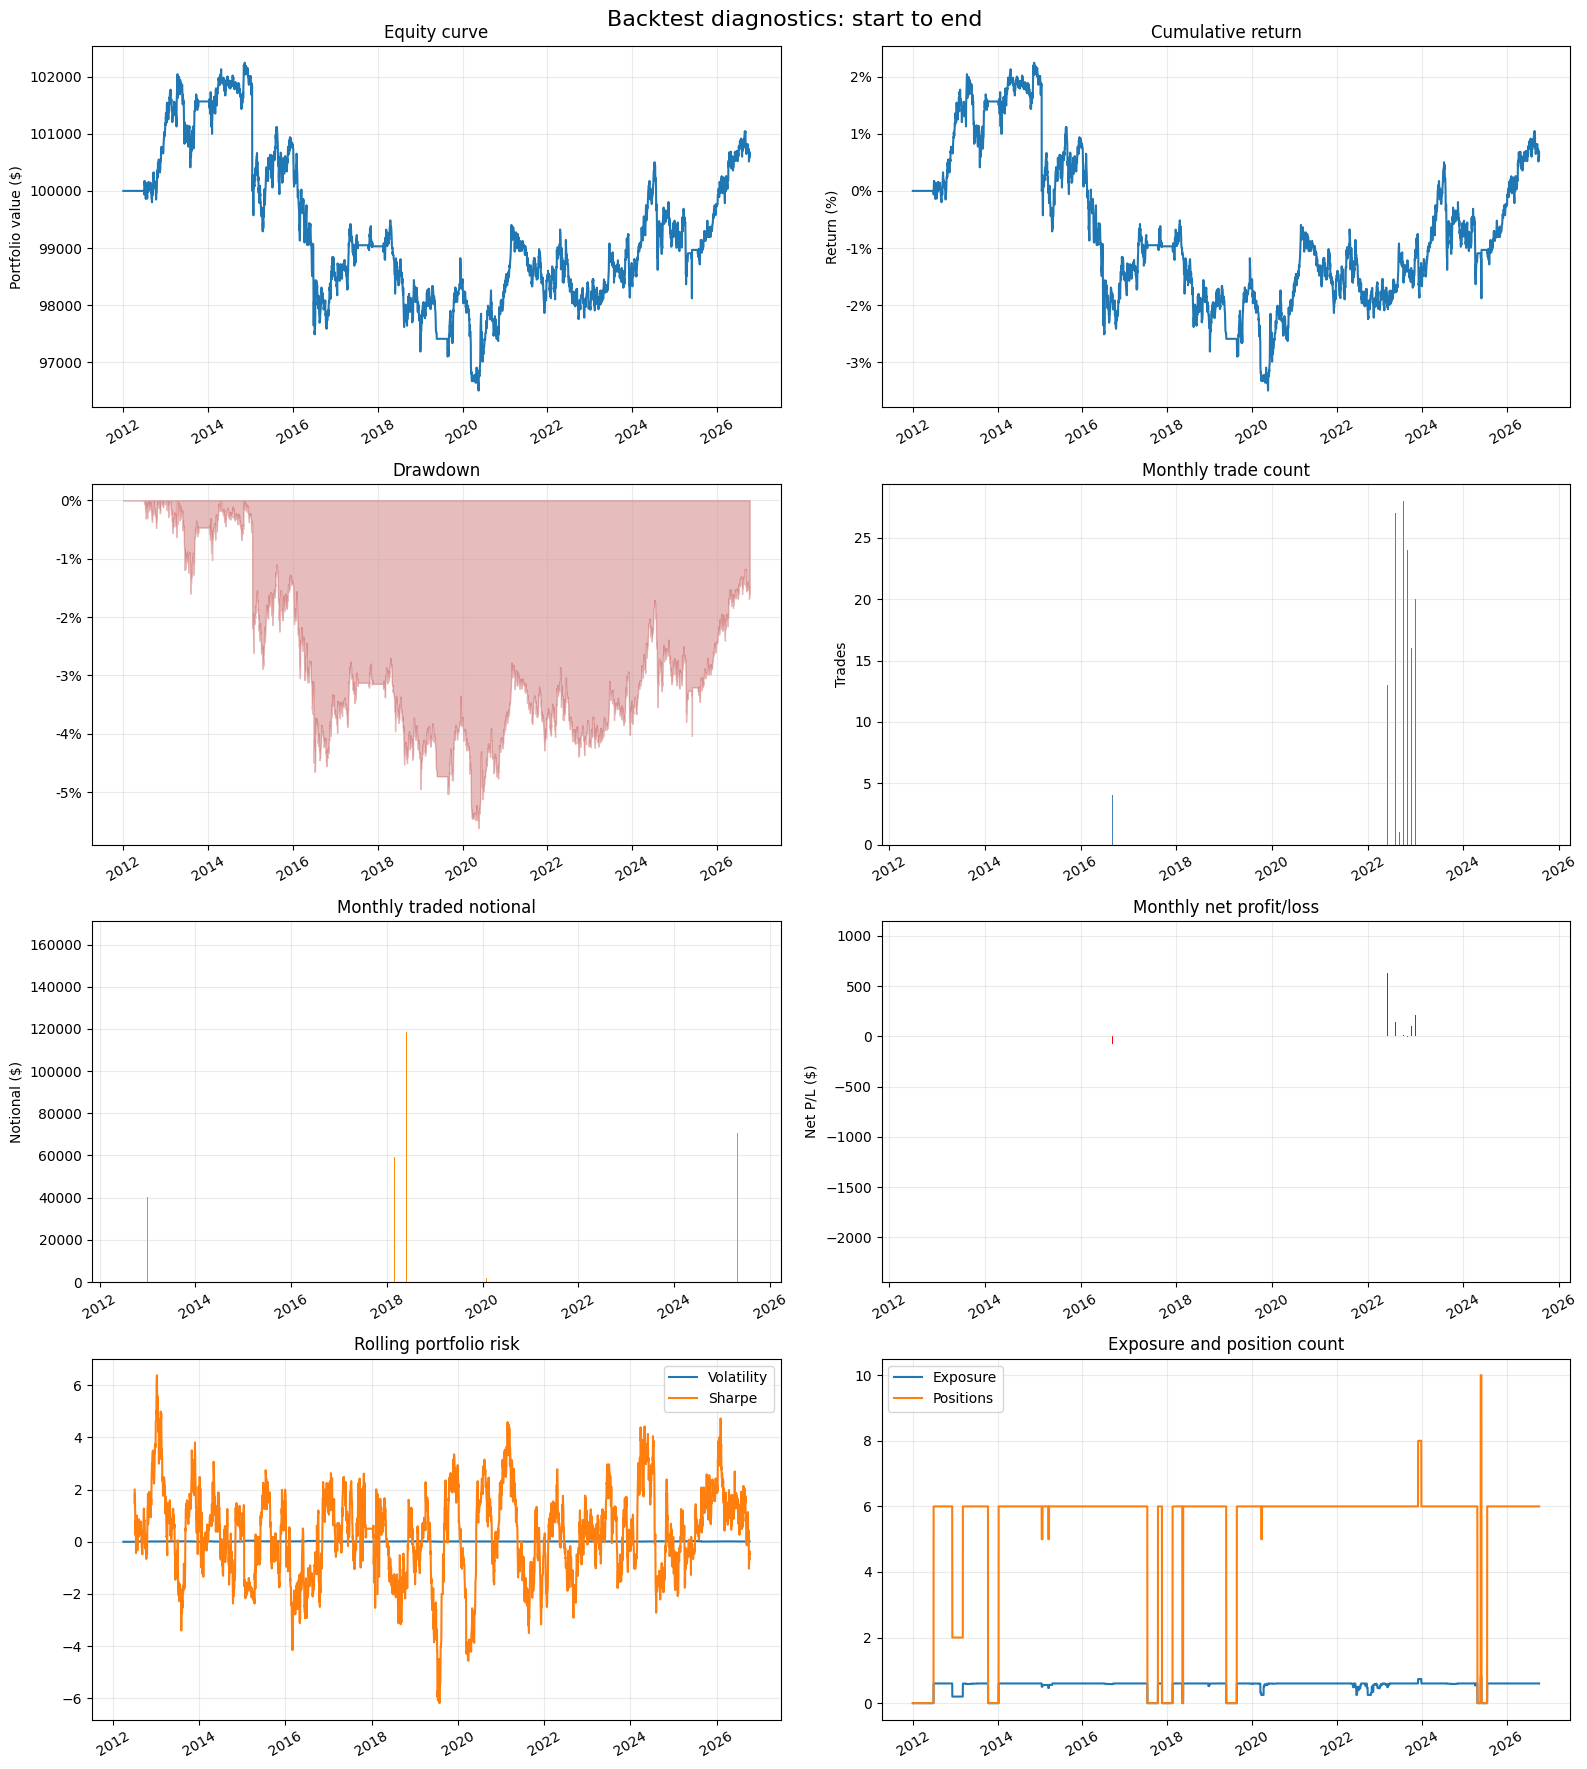

In [3]:
plot_diagnostics(ledger, trades, portfolio_risk, prices[config['benchmark']])


(<Figure size 1600x1800 with 8 Axes>,
 array([<Axes: title={'center': 'Equity curve'}, ylabel='Portfolio value ($)'>,
        <Axes: title={'center': 'Cumulative return'}, ylabel='Return (%)'>,
        <Axes: title={'center': 'Drawdown'}>,
        <Axes: title={'center': 'Monthly trade count'}, ylabel='Trades'>,
        <Axes: title={'center': 'Monthly traded notional'}, ylabel='Notional ($)'>,
        <Axes: title={'center': 'Monthly net profit/loss'}, ylabel='Net P/L ($)'>,
        <Axes: title={'center': 'Rolling portfolio risk'}>,
        <Axes: title={'center': 'Exposure and position count'}>],
       dtype=object))

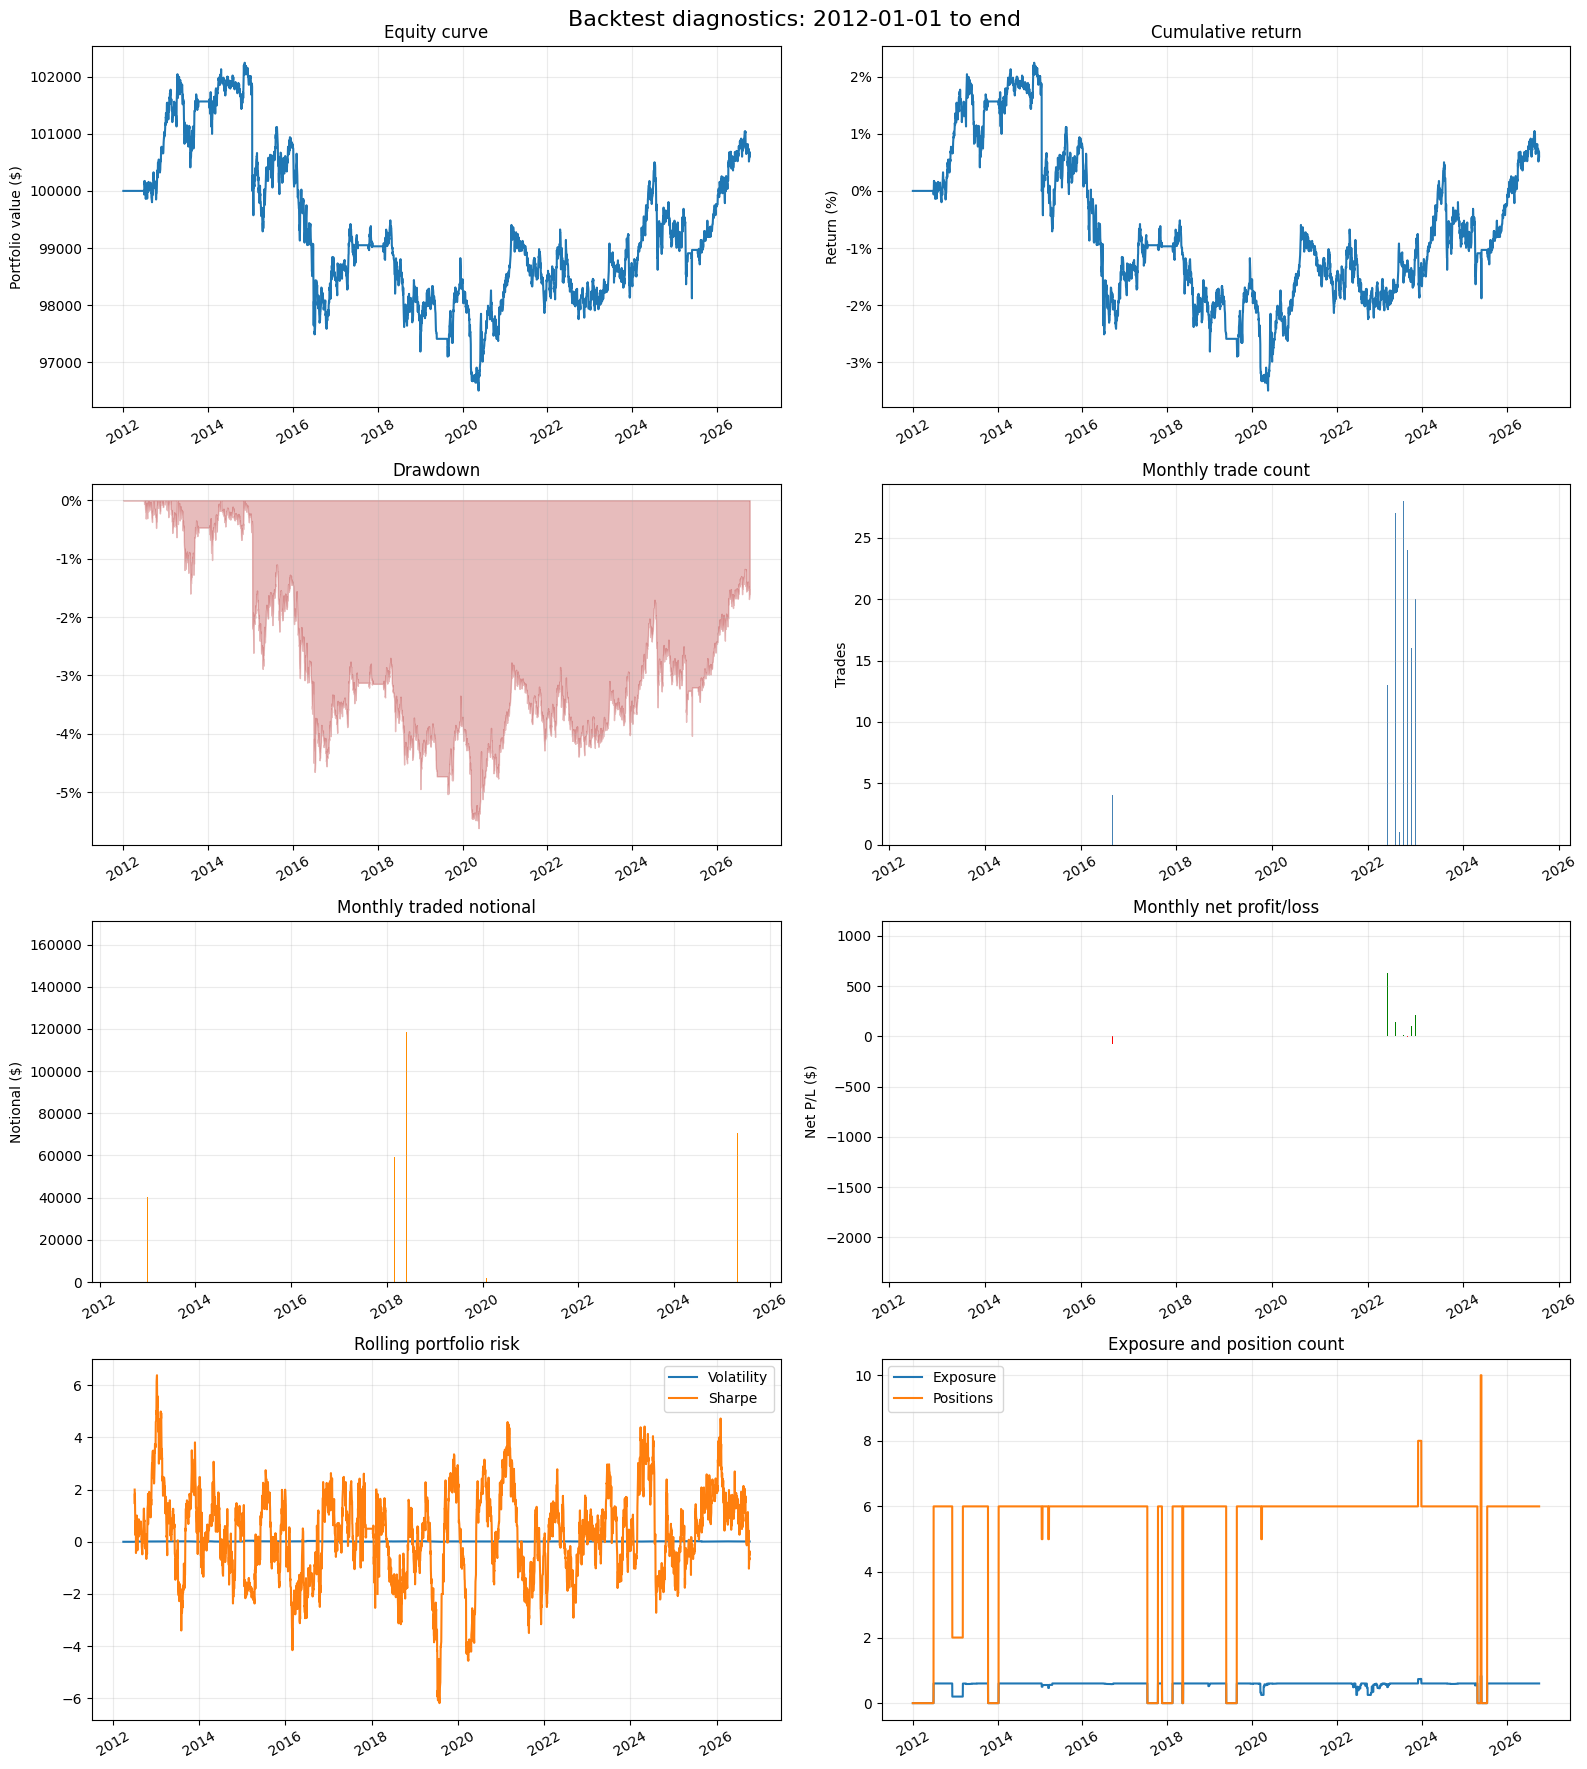

In [4]:
plot_diagnostics(ledger, trades, portfolio_risk, prices[config['benchmark']], start=plot_start, end=plot_end)


(<Figure size 1400x500 with 1 Axes>,
 <Axes: title={'center': 'Five-year returns'}, ylabel='Return (%)'>)

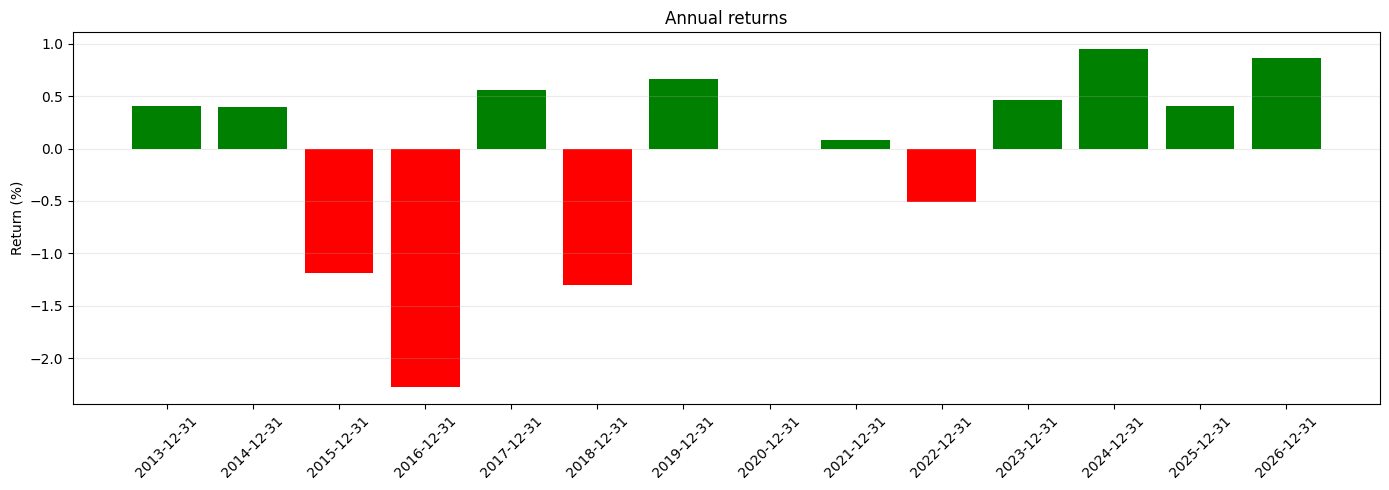

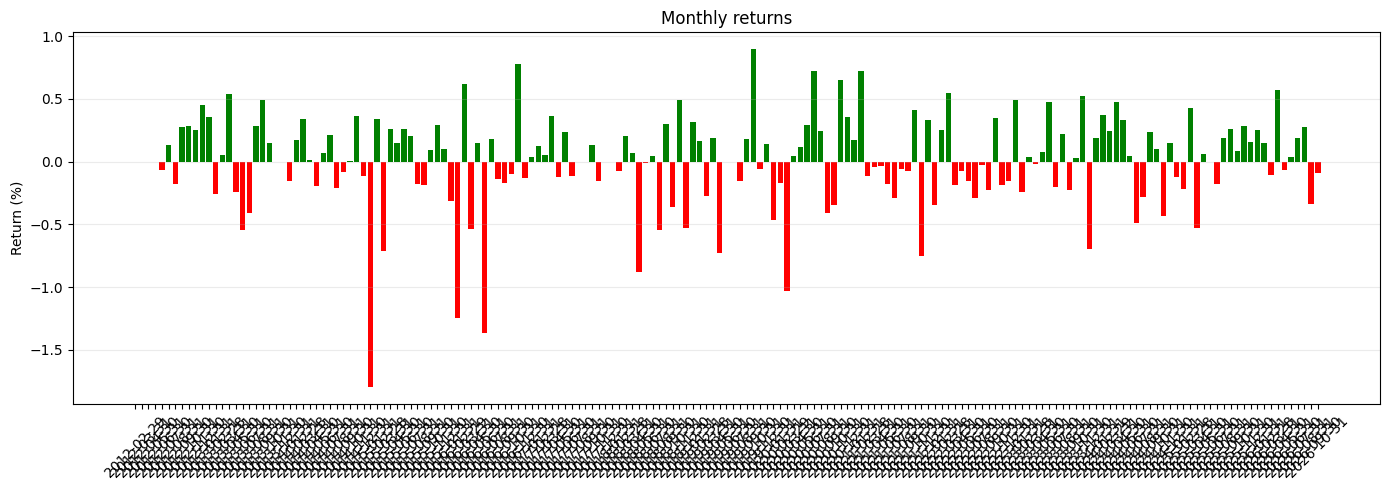

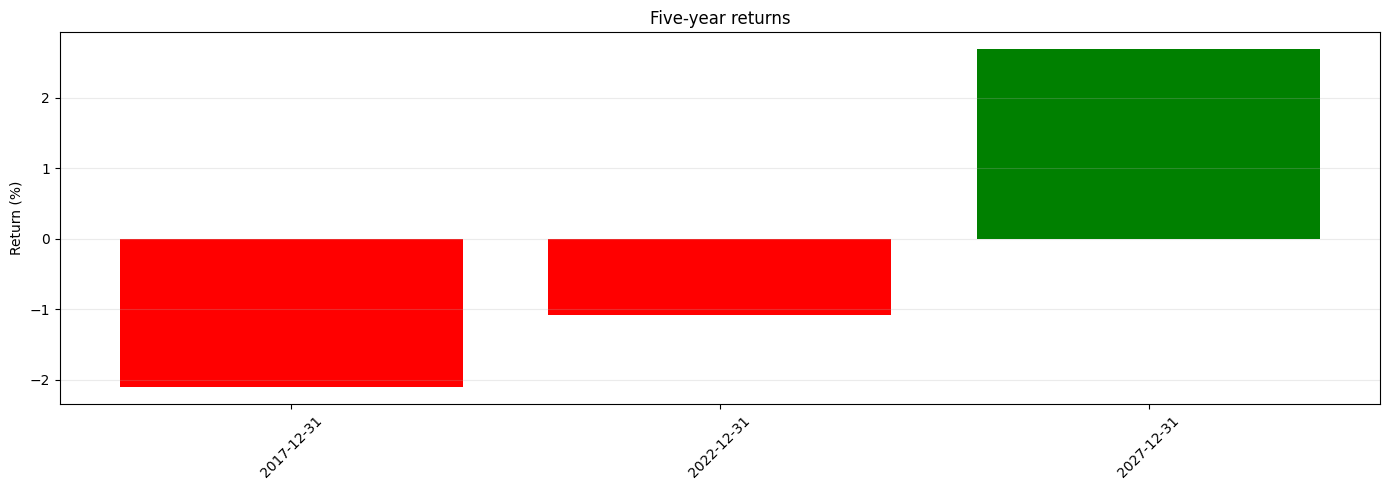

In [5]:
plot_periodic_returns(ledger, period='Y')
plot_periodic_returns(ledger, period='M')
plot_periodic_returns(ledger, period='5Y')


In [6]:
trades.style.format({
    'weight_before': '{:.3%}', 'weight_after': '{:.3%}', 'weight_change': '{:.3%}',
    'execution_price': '${:,.3f}', 'notional': '${:,.3f}', 'estimated_cost': '${:,.3f}',
    'realized_profit_loss': '${:,.3f}', 'net_profit_loss': '${:,.3f}',
    'profit_loss_pct': '{:.3%}', 'cumulative_net_profit_loss': '${:,.3f}',
})


,date,symbol,side,weight_before,weight_after,weight_change,execution_price,notional,estimated_cost,realized_profit_loss,net_profit_loss,profit_loss_pct,cumulative_net_profit_loss
0,2012-06-29 00:00:00,AUDUSD=X,BUY,0.000%,10.000%,10.000%,$1.003,"$10,000.000",$10.500,$0.000,$0.000,0.000%,$0.000
1,2012-06-29 00:00:00,EURUSD=X,BUY,0.000%,10.000%,10.000%,$1.244,"$10,000.000",$10.500,$0.000,$0.000,0.000%,$0.000
2,2012-06-29 00:00:00,GBPUSD=X,BUY,0.000%,10.000%,10.000%,$1.552,"$10,000.000",$10.500,$0.000,$0.000,0.000%,$0.000
3,2012-06-29 00:00:00,USDCAD=X,BUY,0.000%,10.000%,10.000%,$1.033,"$10,000.000",$10.500,$0.000,$0.000,0.000%,$0.000
4,2012-06-29 00:00:00,USDCHF=X,BUY,0.000%,10.000%,10.000%,$0.965,"$10,000.000",$10.500,$0.000,$0.000,0.000%,$0.000
5,2012-06-29 00:00:00,USDJPY=X,BUY,0.000%,10.000%,10.000%,$79.313,"$10,000.000",$10.500,$0.000,$0.000,0.000%,$0.000
6,2012-12-07 00:00:00,AUDUSD=X,SELL,10.000%,0.000%,-10.000%,$1.047,"$10,071.939",$10.576,$423.336,$412.760,4.098%,$412.760
7,2012-12-07 00:00:00,EURUSD=X,SELL,10.000%,0.000%,-10.000%,$1.296,"$10,071.939",$10.576,$405.986,$395.410,3.926%,$808.171
8,2012-12-07 00:00:00,USDCAD=X,SELL,10.000%,0.000%,-10.000%,$0.991,"$10,071.939",$10.576,$-406.523,$-417.098,-4.141%,$391.072
9,2012-12-07 00:00:00,USDCHF=X,SELL,10.000%,0.000%,-10.000%,$0.933,"$10,071.939",$10.576,$-336.935,$-347.511,-3.450%,$43.561
